# 01 Toy Example: Understanding SSSD on a 2D Dataset

This notebook provides a minimal visual demonstration of **SSSD (Similar Scores, Similar Data)**.

The goal is not to reproduce the full experimental results in the paper. Instead, this notebook helps readers quickly understand the intuition behind SSSD:

> Data points with similar characteristics should receive similar anomaly scores.

SSSD identifies points that violate this score-data consistency assumption. A larger SSSD value indicates a stronger local inconsistency between the data distribution and the anomaly scores.

## Step 0: Import Packages

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from pyod.utils.data import generate_data

from pyod.models.iforest import IForest
from pyod.models.lof import LOF
from pyod.models.ocsvm import OCSVM
from pyod.models.knn import KNN
from pyod.models.hbos import HBOS
from pyod.models.abod import ABOD
from pyod.models.loda import LODA
from pyod.models.pca import PCA

In [2]:
import sys
from pathlib import Path

# Make sure SSSD.py in the project root can be imported
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from SSSD import SSSD

## Step 1: Generate a Simple 2D Dataset

We create a two-dimensional dataset.

In [3]:
n_samples = 1000
outliers_fraction = 0.1
n_features=2
rng = np.random.RandomState(42)

In [4]:
X,ground_truth = generate_data(n_train=n_samples,n_features=n_features,contamination=outliers_fraction, train_only=True,random_state=rng)

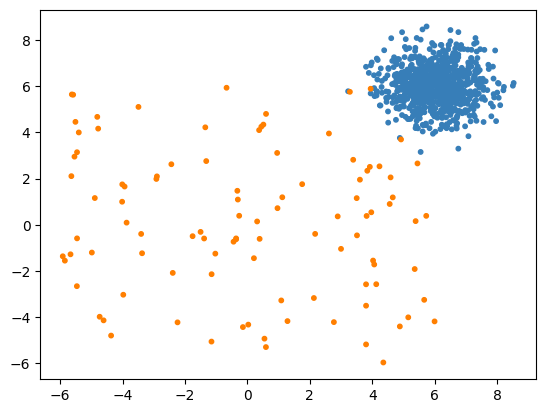

In [5]:
colors = np.array(["#377eb8", "#ff7f00"])
plt.scatter(X[:, 0], X[:, 1], s=10, color=colors[(ground_truth.astype(int) + 1) // 2])

## Step 2: Evaluations on different anomaly detection methods

We train unsupervised anomaly detectors to obtain anomaly scores and visualize these scores in the figure. The transparency of each data point corresponds to its anomaly score. We then use SSSD to evaluate the performance of the detectors.


In [6]:
anomaly_algorithms = [
    ("LODA",LODA(contamination=outliers_fraction)),
    ("ABOD",ABOD(contamination=outliers_fraction)),
    ("iForest",IForest(contamination=outliers_fraction)),
    ('kNN',KNN(contamination=outliers_fraction)),
    ('LOF',LOF(contamination=outliers_fraction)),
    ("HBOS",HBOS(contamination=outliers_fraction)),
    ("OCSVM",OCSVM(contamination=outliers_fraction)),
    ("PCA",PCA(contamination=outliers_fraction))
]


LODA
Score-based SSSD: 3.264574244199689
Distance-based SSSD: 7.999856232925578
Final SSSD: 5.632215238562633

ABOD
Score-based SSSD: 2.1730299729903786
Distance-based SSSD: 5.411895212162653
Final SSSD: 3.7924625925765154

iForest
Score-based SSSD: 2.989996189240763
Distance-based SSSD: 6.89775504115466
Final SSSD: 4.943875615197711

kNN
Score-based SSSD: 4.617468534231898
Distance-based SSSD: 2.8939878937513166
Final SSSD: 3.755728213991607

LOF
Score-based SSSD: 6.3247085437694315
Distance-based SSSD: 21.809591821769295
Final SSSD: 14.067150182769364

HBOS
Score-based SSSD: 9.25580704793105
Distance-based SSSD: 8.763305440233015
Final SSSD: 9.009556244082033

OCSVM
Score-based SSSD: 2.104147864650397
Distance-based SSSD: 4.2416740434682145
Final SSSD: 3.1729109540593052

PCA
Score-based SSSD: 1.3080806264844802
Distance-based SSSD: 9.363443757979383
Final SSSD: 5.335762192231932


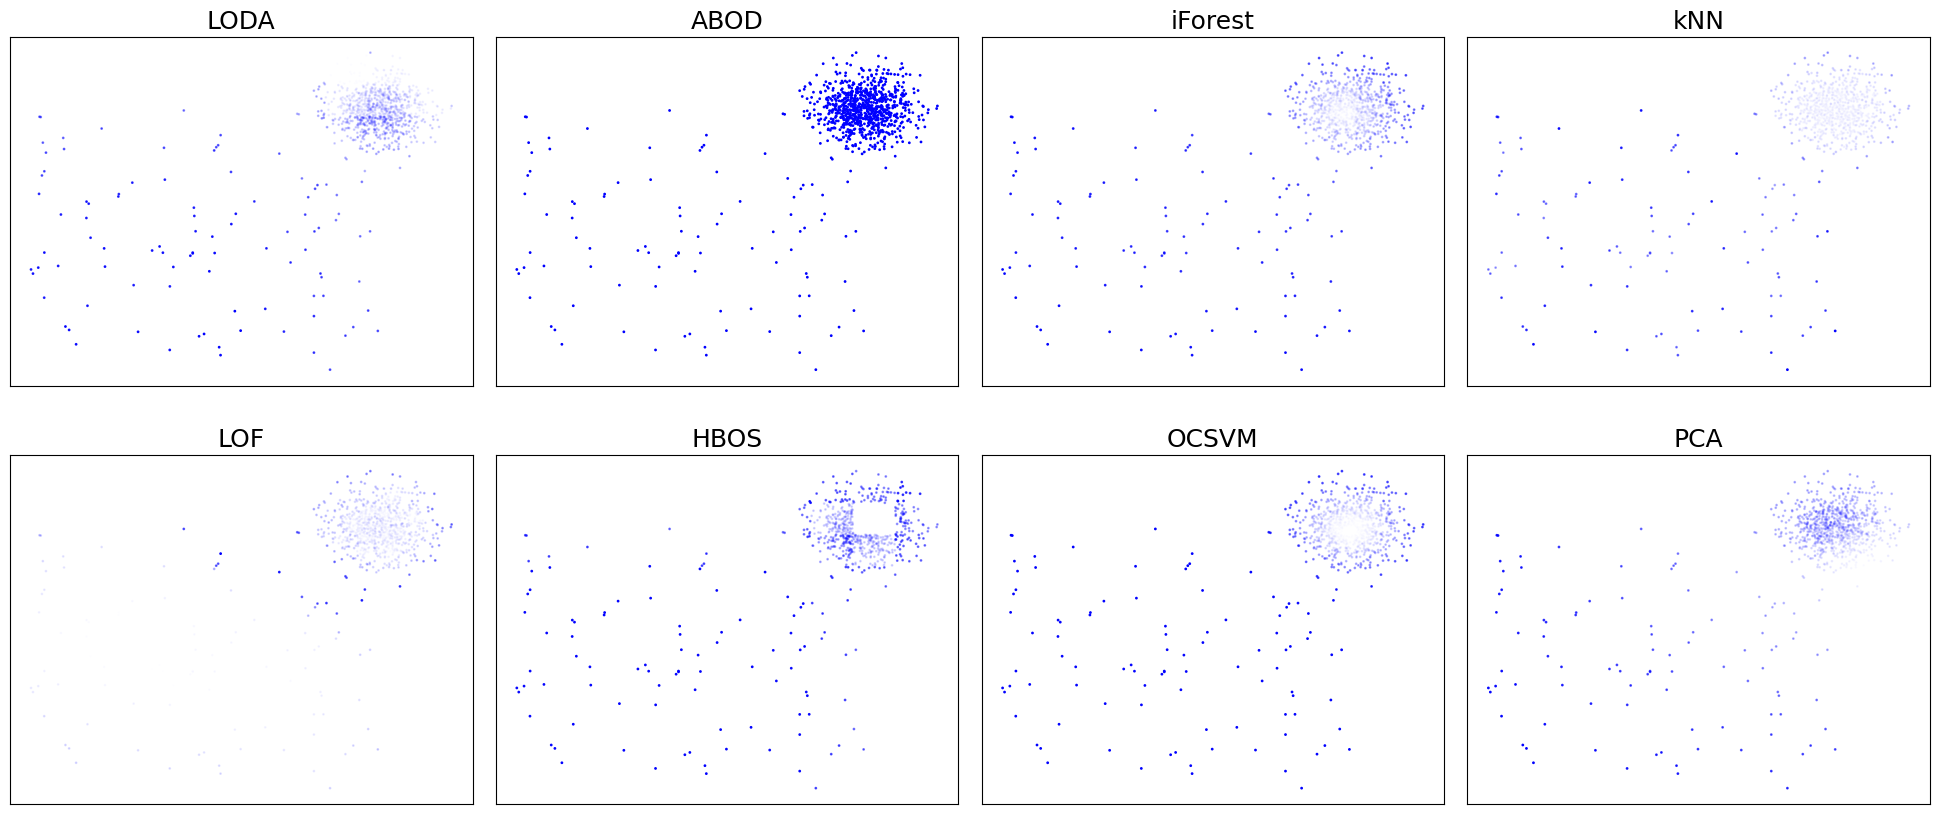

In [7]:
# Evaluate the results of anomaly detection algorithms
plt.figure(figsize=(len(anomaly_algorithms) * 2 + 4, 8))
plt.subplots_adjust(left=0.02, right=0.98, bottom=0.001, top=0.96, wspace=0.05, hspace=0.2)

# Iterate over each algorithm and evaluate
for plot_num, (name, algorithm) in enumerate(anomaly_algorithms, start=1):
    # Fit and predict anomaly scores
    algorithm.fit(X)
    scores = algorithm.decision_function(X)
    
    # Normalize scores between 0 and 1
    scores = (scores - np.min(scores)) / (np.max(scores) - np.min(scores))
    
    # Compute SSSD scores
    sssd = SSSD(X, scores)
    
    print(f"\n{name}")
    _, score_sssd_sum, _ = sssd.get_Score_SSSD()
    print(f"Score-based SSSD: {score_sssd_sum}")
    
    _, distance_sssd_sum, _ = sssd.get_Distance_SSSD()
    print(f"Distance-based SSSD: {distance_sssd_sum}")
    
    _, final_sssd_sum, _ = sssd.get_final_SSSD()
    print(f"Final SSSD: {final_sssd_sum}")
    
    
    
    # Plot results
    plt.subplot(2, 4, plot_num)
    plt.title(name, size=18)
    plt.scatter(X[:, 0], X[:, 1], s=1, color='b', alpha=scores)
    plt.xticks(())
    plt.yticks(())

plt.show()


## Step 3: Interpretability on different anomaly detection methods using Distance SSSD
Highlight the top 50 Distance SSSD points with red circles. Higher SSSD scores indicate a higher probability of being mislabeled.

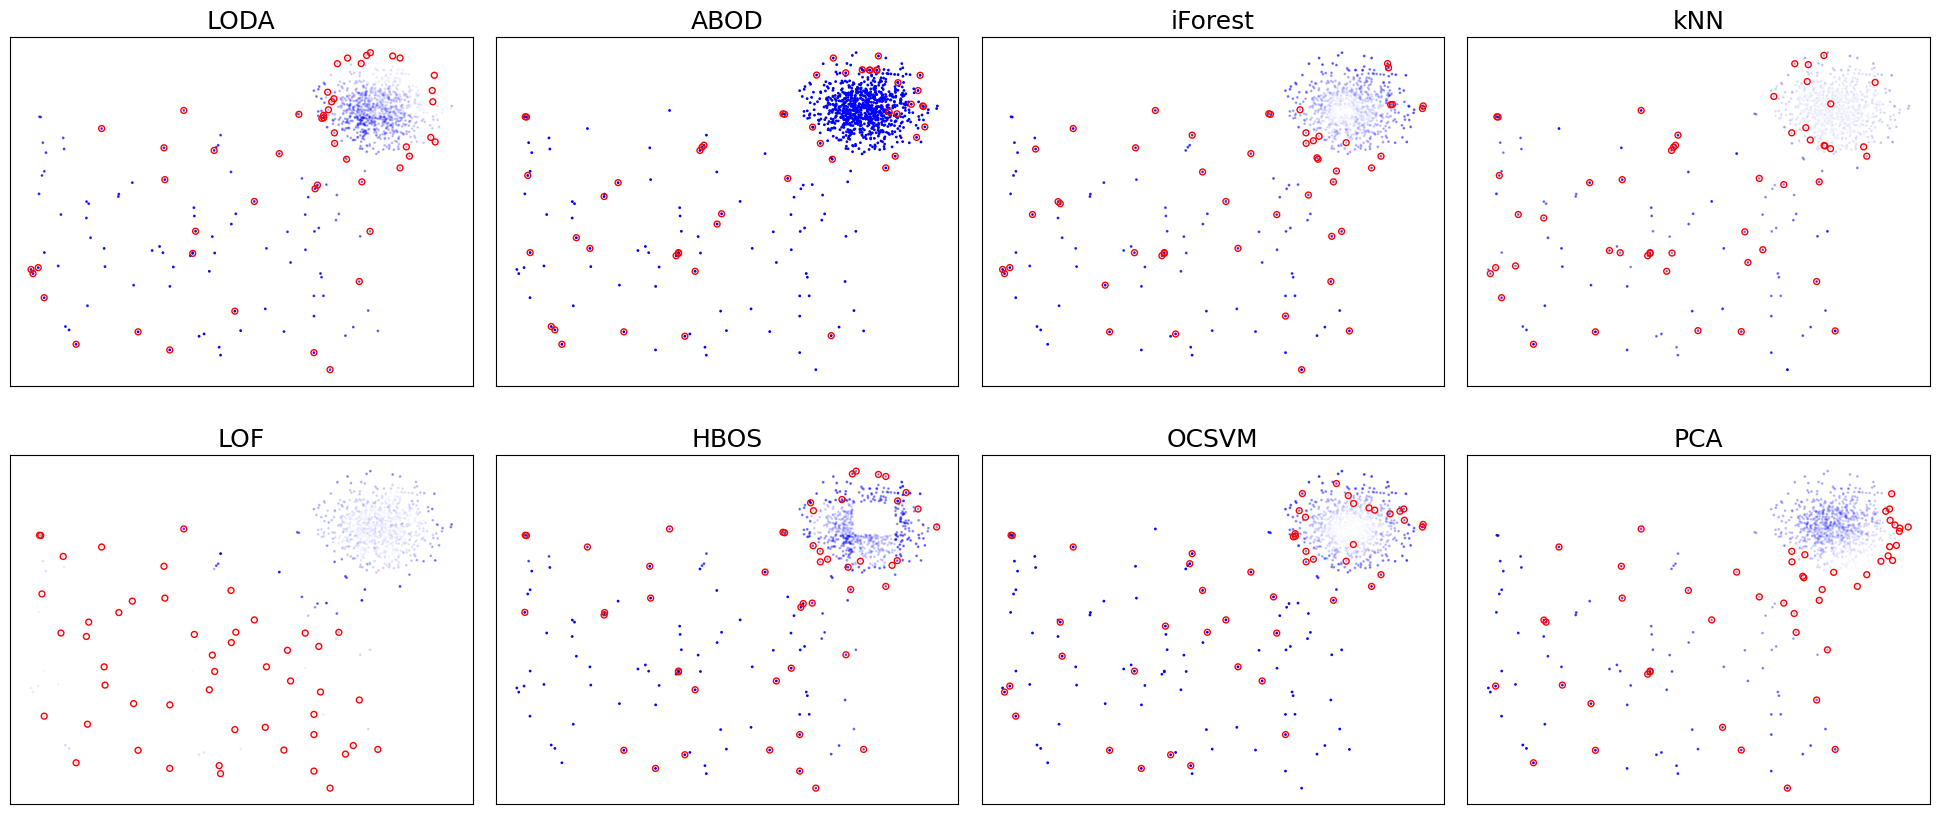

In [8]:
# Set up the plot
plt.figure(figsize=(len(anomaly_algorithms) * 2 + 4, 8))
plt.subplots_adjust(left=0.02, right=0.98, bottom=0.001, top=0.96, wspace=0.05, hspace=0.2)

# Iterate through each anomaly detection algorithm
for plot_num, (name, algorithm) in enumerate(anomaly_algorithms, start=1):
    # Fit the algorithm to the data
    algorithm.fit(X)
    
    # Predict anomalies and compute anomaly scores
    y_pred = algorithm.predict(X)
    scores = algorithm.decision_function(X)
    scores = (scores - np.min(scores)) / (np.max(scores) - np.min(scores))  # Normalize scores

    # Use SSSD class to calculate Distance-based SSSD and get mislabled points
    sssd = SSSD(X, scores)
    _, _, index = sssd.get_Distance_SSSD()

    # Create subplot for the algorithm
    plt.subplot(2, 4, plot_num)
    plt.title(name, size=18)

    # Plot the data points, with color intensity based on the anomaly score
    plt.scatter(X[:, 0], X[:, 1], s=1, color='b', alpha=scores)

    # Highlight the top 50 points with the largest SSSD values using red circles
    plt.scatter(X[index[:50], 0], X[index[:50], 1], c='none', edgecolors='r', marker='o', s=18)

    # Remove axis labels for clarity
    plt.xticks(())
    plt.yticks(())

# Show the plot
plt.show()


## Step 4: Interpretability on different anomaly detection methods using Score SSSD
Highlight the top 50 Score SSSD points with red circles. Higher SSSD scores indicate a higher probability of being mislabeled.

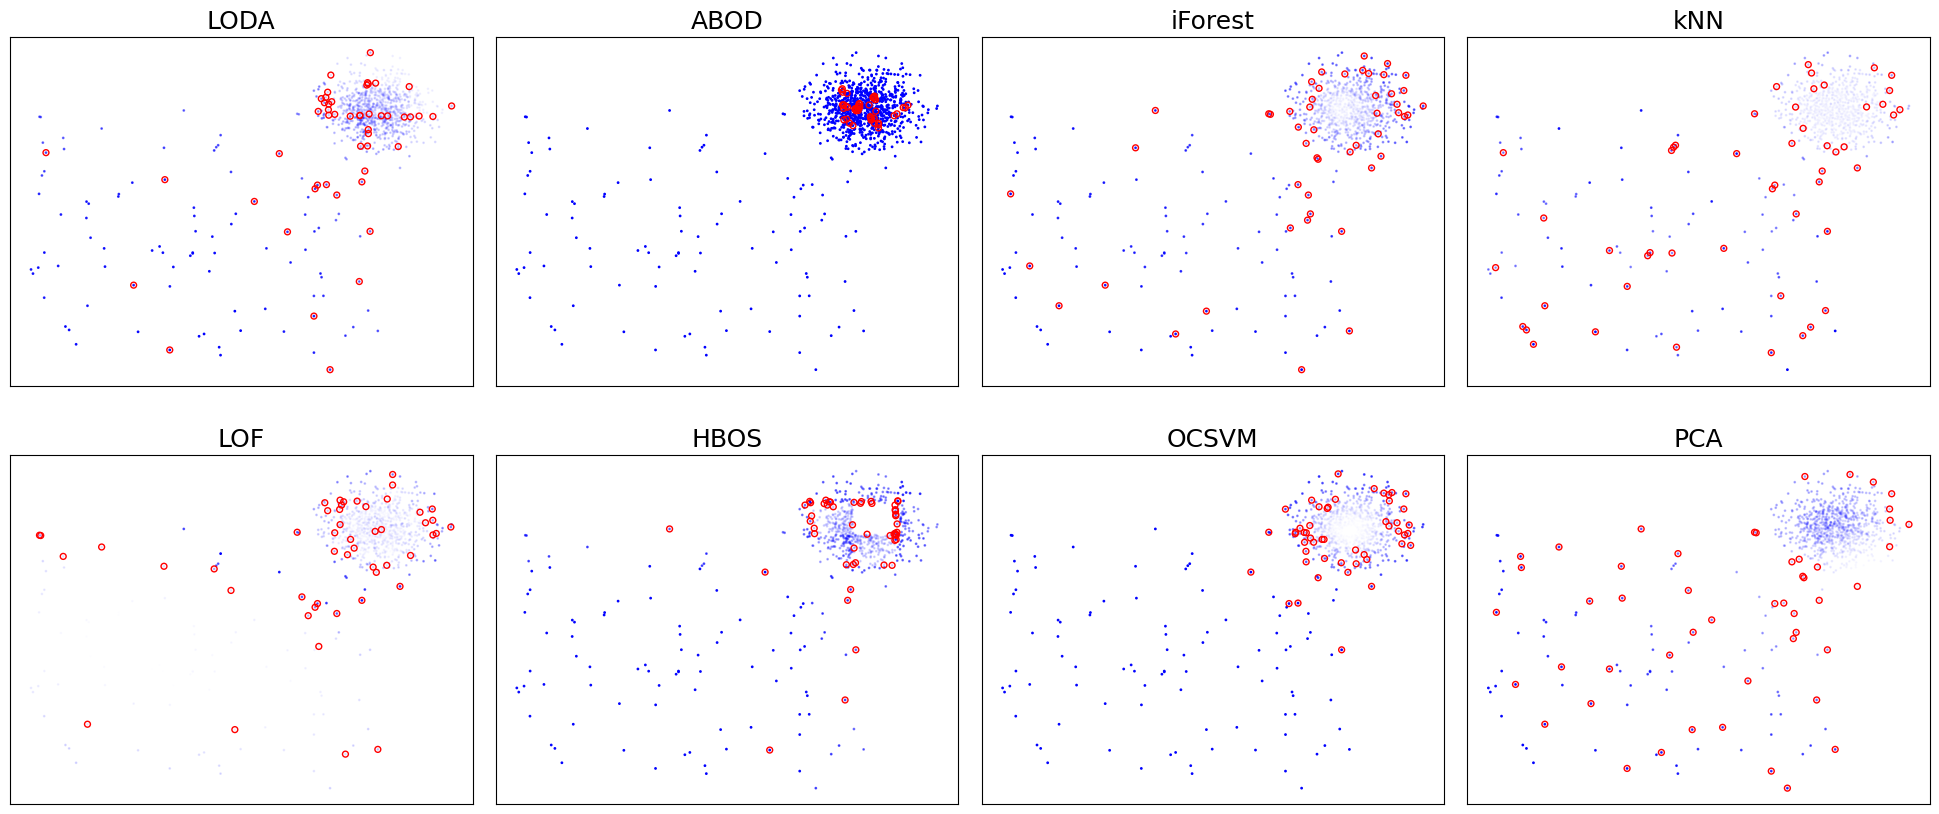

In [9]:
# Set up the plot
plt.figure(figsize=(len(anomaly_algorithms) * 2 + 4, 8))
plt.subplots_adjust(left=0.02, right=0.98, bottom=0.001, top=0.96, wspace=0.05, hspace=0.2)

# Iterate through each anomaly detection algorithm
for plot_num, (name, algorithm) in enumerate(anomaly_algorithms, start=1):
    # Fit the algorithm to the data
    algorithm.fit(X)
    
    # Predict anomalies and compute anomaly scores
    y_pred = algorithm.predict(X)
    scores = algorithm.decision_function(X)
    scores = (scores - np.min(scores)) / (np.max(scores) - np.min(scores))  # Normalize scores

    # Use SSSD class to calculate Score-based SSSD and get mislabled points
    sssd = SSSD(X, scores)
    _, _, index = sssd.get_Score_SSSD()

    # Create subplot for the algorithm
    plt.subplot(2, 4, plot_num)
    plt.title(name, size=18)

    # Plot the data points, with color intensity based on the anomaly score
    plt.scatter(X[:, 0], X[:, 1], s=1, color='b', alpha=scores)

    # Highlight the top 50 points with the largest SSSD values using red circles
    plt.scatter(X[index[:50], 0], X[index[:50], 1], c='none', edgecolors='r', marker='o', s=18)

    # Remove axis labels for clarity
    plt.xticks(())
    plt.yticks(())

# Show the plot
plt.show()


## Summary

This toy example illustrates the basic usage and intuition of SSSD:

- SSSD evaluates anomaly scores without using labels.
- Larger SSSD values indicate stronger violations of score-data consistency.
- High-SSSD samples can be inspected as potentially unreliable or suspicious detection results.
  
For more complete experiments, please refer to:

- `02_synthetic_experiments.ipynb`
- `03_realworld_experiments.ipynb`